In [2]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles and folders here:")
print(os.listdir())

Current folder:
C:\Users\mural\OneDrive\Desktop\Healthcare_Triage

Files and folders here:
['.ipynb_checkpoints', '01_dataset_preparation.ipynb', 'data', 'models', 'notebooks']


In [3]:
import os

print("Files inside data folder:")

print(os.listdir("data"))

Files inside data folder:
['.ipynb_checkpoints', 'chief_complaints.csv', 'NOTE.md', 'patient_history.csv', 'sample_submission.csv', 'test.csv', 'train.csv']


In [4]:
import pandas as pd

# Load the datasets
train = pd.read_csv("data/train.csv")

complaints = pd.read_csv(
    "data/chief_complaints.csv"
)

history = pd.read_csv(
    "data/patient_history.csv"
)

print("Training data:", train.shape)
print("Chief complaints:", complaints.shape)
print("Patient history:", history.shape)

Training data: (80000, 40)
Chief complaints: (100000, 3)
Patient history: (100000, 26)


In [5]:
print("TRAIN COLUMNS:")
print(train.columns.tolist())

print("\nCHIEF COMPLAINTS COLUMNS:")
print(complaints.columns.tolist())

print("\nPATIENT HISTORY COLUMNS:")
print(history.columns.tolist())

TRAIN COLUMNS:
['patient_id', 'site_id', 'triage_nurse_id', 'arrival_mode', 'arrival_hour', 'arrival_day', 'arrival_month', 'arrival_season', 'shift', 'age', 'age_group', 'sex', 'language', 'insurance_type', 'transport_origin', 'pain_location', 'mental_status_triage', 'chief_complaint_system', 'num_prior_ed_visits_12m', 'num_prior_admissions_12m', 'num_active_medications', 'num_comorbidities', 'systolic_bp', 'diastolic_bp', 'mean_arterial_pressure', 'pulse_pressure', 'heart_rate', 'respiratory_rate', 'temperature_c', 'spo2', 'gcs_total', 'pain_score', 'weight_kg', 'height_cm', 'bmi', 'shock_index', 'news2_score', 'disposition', 'ed_los_hours', 'triage_acuity']

CHIEF COMPLAINTS COLUMNS:
['patient_id', 'chief_complaint_raw', 'chief_complaint_system']

PATIENT HISTORY COLUMNS:
['patient_id', 'hx_hypertension', 'hx_diabetes_type2', 'hx_diabetes_type1', 'hx_asthma', 'hx_copd', 'hx_heart_failure', 'hx_atrial_fibrillation', 'hx_ckd', 'hx_liver_disease', 'hx_malignancy', 'hx_obesity', 'hx_dep

In [6]:

train_merged = train.merge(
    complaints[["patient_id", "chief_complaint_raw"]],
    on="patient_id",
    how="left",
    validate="one_to_one"
)

# Merge patient medical history
train_merged = train_merged.merge(
    history,
    on="patient_id",
    how="left",
    validate="one_to_one"
)

print("All datasets merged successfully!")
print("Final dataset shape:", train_merged.shape)

train_merged.head()

All datasets merged successfully!
Final dataset shape: (80000, 66)


,patient_id,site_id,triage_nurse_id,arrival_mode,arrival_hour,arrival_day,arrival_month,arrival_season,shift,age,...,hx_hypothyroidism,hx_hyperthyroidism,hx_hiv,hx_coagulopathy,hx_immunosuppressed,hx_pregnant,hx_substance_use_disorder,hx_coronary_artery_disease,hx_stroke_prior,hx_peripheral_vascular_disease
0,TG-UXRGA9UCO,SITE-TMP-01,NURSE-0033,walk-in,6,Monday,5,spring,morning,43,...,1,1,0,0,1,0,0,0,0,0
1,TG-B19DBBS2G,SITE-HEL-01,NURSE-0001,walk-in,6,Thursday,4,spring,morning,72,...,1,0,0,0,1,0,1,1,0,0
2,TG-GZ97W7M6V,SITE-HEL-02,NURSE-0005,walk-in,8,Saturday,4,spring,morning,82,...,0,1,1,0,0,0,0,1,1,1
3,TG-THIB2TN9Q,SITE-HEL-02,NURSE-0026,police,7,Sunday,3,spring,morning,50,...,0,0,1,0,1,0,0,0,0,1
4,TG-J3U3LQ2QY,SITE-HEL-02,NURSE-0044,walk-in,5,Tuesday,5,spring,night,62,...,1,1,0,1,1,0,1,1,1,0


In [7]:
train_merged.to_csv(
    "data/triage_training_merged.csv",
    index=False
)

print("Final dataset saved successfully!")

Final dataset saved successfully!


In [8]:
print("Rows:", train_merged.shape[0])
print("Columns:", train_merged.shape[1])

print("\nTarget categories:")
print(train_merged["triage_acuity"].value_counts().sort_index())

print("\nMissing symptom descriptions:")
print(train_merged["chief_complaint_raw"].isnull().sum())

print("\nFirst 5 patient records:")
display(train_merged.head())

Rows: 80000
Columns: 66

Target categories:
triage_acuity
1     3222
2    13439
3    28921
4    23020
5    11398
Name: count, dtype: int64

Missing symptom descriptions:
0

First 5 patient records:


,patient_id,site_id,triage_nurse_id,arrival_mode,arrival_hour,arrival_day,arrival_month,arrival_season,shift,age,...,hx_hypothyroidism,hx_hyperthyroidism,hx_hiv,hx_coagulopathy,hx_immunosuppressed,hx_pregnant,hx_substance_use_disorder,hx_coronary_artery_disease,hx_stroke_prior,hx_peripheral_vascular_disease
0,TG-UXRGA9UCO,SITE-TMP-01,NURSE-0033,walk-in,6,Monday,5,spring,morning,43,...,1,1,0,0,1,0,0,0,0,0
1,TG-B19DBBS2G,SITE-HEL-01,NURSE-0001,walk-in,6,Thursday,4,spring,morning,72,...,1,0,0,0,1,0,1,1,0,0
2,TG-GZ97W7M6V,SITE-HEL-02,NURSE-0005,walk-in,8,Saturday,4,spring,morning,82,...,0,1,1,0,0,0,0,1,1,1
3,TG-THIB2TN9Q,SITE-HEL-02,NURSE-0026,police,7,Sunday,3,spring,morning,50,...,0,0,1,0,1,0,0,0,0,1
4,TG-J3U3LQ2QY,SITE-HEL-02,NURSE-0044,walk-in,5,Tuesday,5,spring,night,62,...,1,1,0,1,1,0,1,1,1,0


In [9]:
df = pd.read_csv("data/triage_training_merged.csv")

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(80000, 66)


In [10]:
# Check column names
print(df.columns.tolist())

# Check data types and missing values
df.info()

['patient_id', 'site_id', 'triage_nurse_id', 'arrival_mode', 'arrival_hour', 'arrival_day', 'arrival_month', 'arrival_season', 'shift', 'age', 'age_group', 'sex', 'language', 'insurance_type', 'transport_origin', 'pain_location', 'mental_status_triage', 'chief_complaint_system', 'num_prior_ed_visits_12m', 'num_prior_admissions_12m', 'num_active_medications', 'num_comorbidities', 'systolic_bp', 'diastolic_bp', 'mean_arterial_pressure', 'pulse_pressure', 'heart_rate', 'respiratory_rate', 'temperature_c', 'spo2', 'gcs_total', 'pain_score', 'weight_kg', 'height_cm', 'bmi', 'shock_index', 'news2_score', 'disposition', 'ed_los_hours', 'triage_acuity', 'chief_complaint_raw', 'hx_hypertension', 'hx_diabetes_type2', 'hx_diabetes_type1', 'hx_asthma', 'hx_copd', 'hx_heart_failure', 'hx_atrial_fibrillation', 'hx_ckd', 'hx_liver_disease', 'hx_malignancy', 'hx_obesity', 'hx_depression', 'hx_anxiety', 'hx_dementia', 'hx_epilepsy', 'hx_hypothyroidism', 'hx_hyperthyroidism', 'hx_hiv', 'hx_coagulopathy'

In [11]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(
    ascending=False
)

print(missing)

systolic_bp               4146
diastolic_bp              4146
mean_arterial_pressure    4146
pulse_pressure            4146
shock_index               4146
respiratory_rate          3067
temperature_c              574
dtype: int64


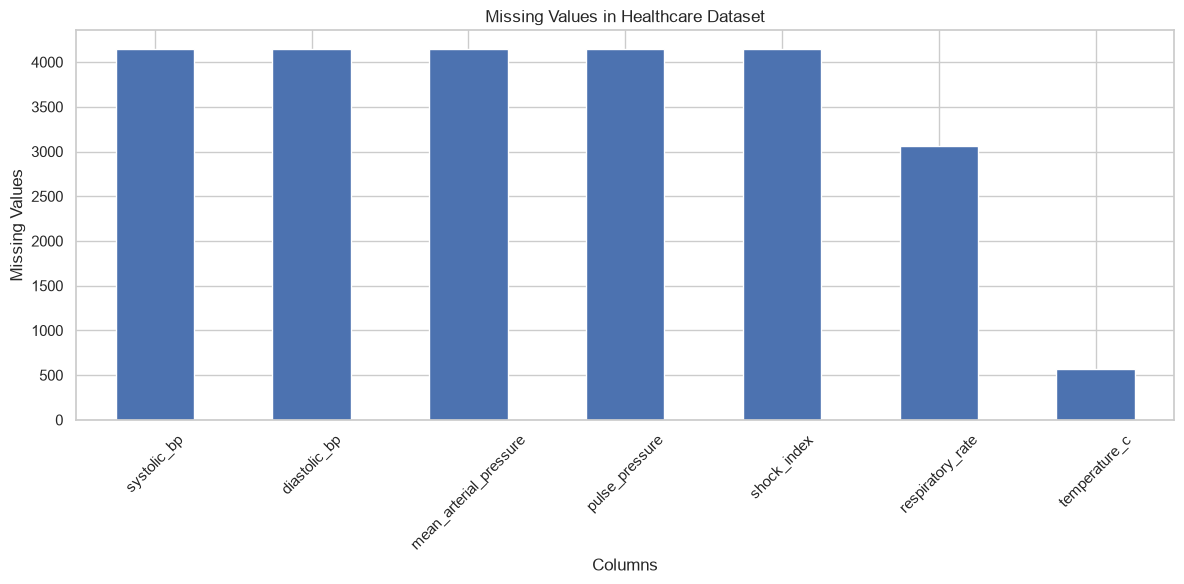

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

missing.plot(kind="bar")

plt.title("Missing Values in Healthcare Dataset")
plt.xlabel("Columns")
plt.ylabel("Missing Values")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [13]:
print(df["triage_acuity"].value_counts().sort_index())

triage_acuity
1     3222
2    13439
3    28921
4    23020
5    11398
Name: count, dtype: int64


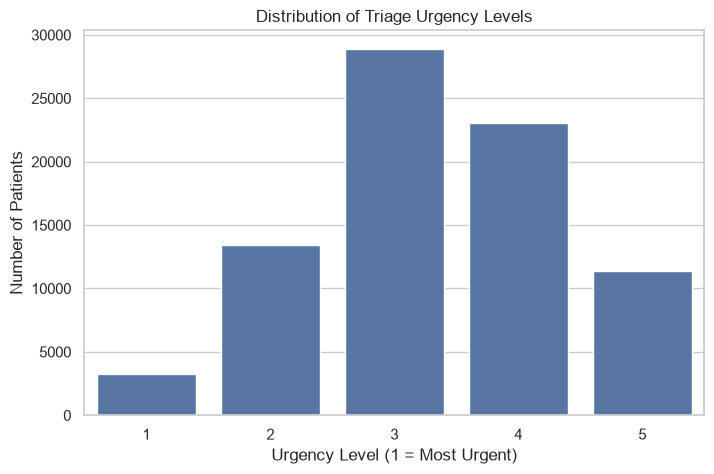

In [14]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="triage_acuity",
    order=sorted(df["triage_acuity"].dropna().unique())
)

plt.title("Distribution of Triage Urgency Levels")
plt.xlabel("Urgency Level (1 = Most Urgent)")
plt.ylabel("Number of Patients")

plt.show()

In [15]:
top_symptoms = (
    df["chief_complaint_raw"]
    .dropna()
    .value_counts()
    .head(10)
)

print(top_symptoms)

chief_complaint_raw
STI with systemic features in known patient                   44
new-onset jaundice with vomiting                              43
sudden visual blurring, for 2 days                            41
chest tightness with dyspnoea, onset today                    41
exertional chest pain with associated nausea                  41
electrolyte imbalance symptomatic，worsening over hours        41
electrolyte imbalance symptomatic, worsening with movement    41
acute stress reaction, worsening with movement                41
substance intoxication, onset today                           40
moderate low back pain, for 2 days                            40
Name: count, dtype: int64


C:\Users\mural\AppData\Local\Temp\ipykernel_30548\1509020974.py:9: UserWarning: Glyph 65292 (\N{FULLWIDTH COMMA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\mural\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65292 (\N{FULLWIDTH COMMA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


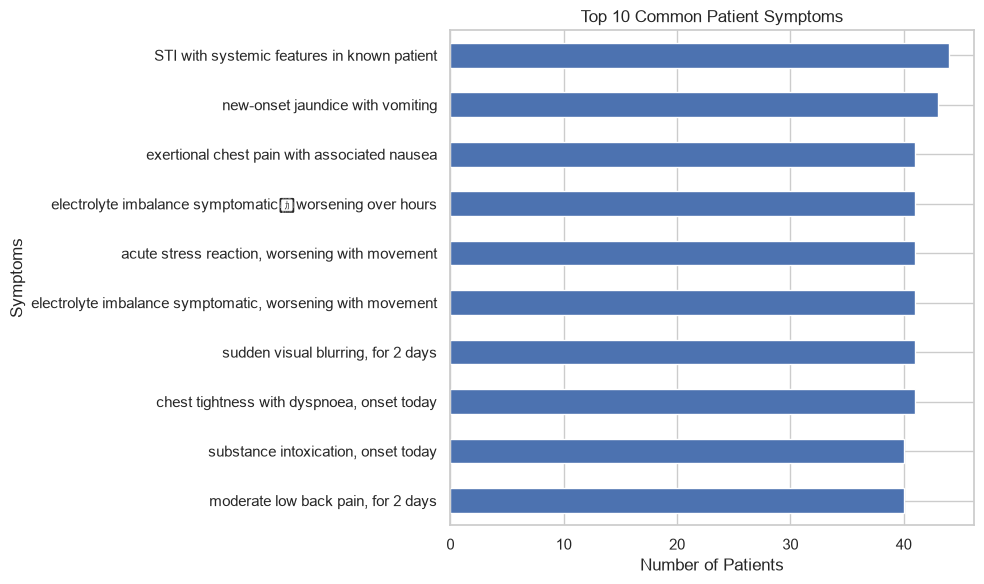

In [16]:
plt.figure(figsize=(10, 6))

top_symptoms.sort_values().plot(kind="barh")

plt.title("Top 10 Common Patient Symptoms")
plt.xlabel("Number of Patients")
plt.ylabel("Symptoms")

plt.tight_layout()
plt.show()

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.family"] = "DejaVu Sans"

sns.set_theme(style="whitegrid")

print("Font settings updated!")

Font settings updated!


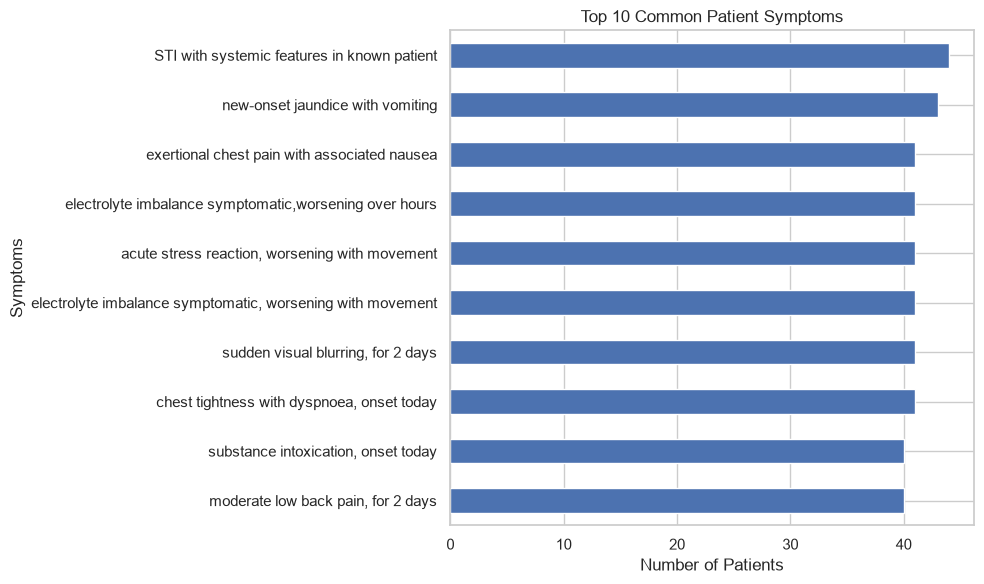

In [18]:
top_symptoms = (
    df["chief_complaint_raw"]
    .dropna()
    .value_counts()
    .head(10)
)

top_symptoms.index = top_symptoms.index.str.replace(
    "，", ",", regex=False
)

plt.figure(figsize=(10, 6))
top_symptoms.sort_values().plot(kind="barh")

plt.title("Top 10 Common Patient Symptoms")
plt.xlabel("Number of Patients")
plt.ylabel("Symptoms")

plt.tight_layout()
plt.show()

In [19]:
vital_columns = [
    "heart_rate",
    "systolic_bp",
    "diastolic_bp",
    "spo2",
    "temperature_c",
    "respiratory_rate"
]

df[vital_columns].describe().round(2)

,heart_rate,systolic_bp,diastolic_bp,spo2,temperature_c,respiratory_rate
count,80000.00,75854.00,75854.00,80000.00,79426.00,76933.00
mean,91.86,121.61,74.45,95.79,37.63,18.33
std,19.49,24.22,14.29,4.31,0.86,4.65
min,30.00,40.00,20.00,60.40,35.10,8.00
25%,78.20,106.20,65.50,94.10,37.00,15.20
50%,89.60,123.10,75.30,97.00,37.50,17.30
75%,103.20,138.30,84.20,98.90,38.10,20.30
max,207.70,226.90,134.80,100.00,41.80,51.50


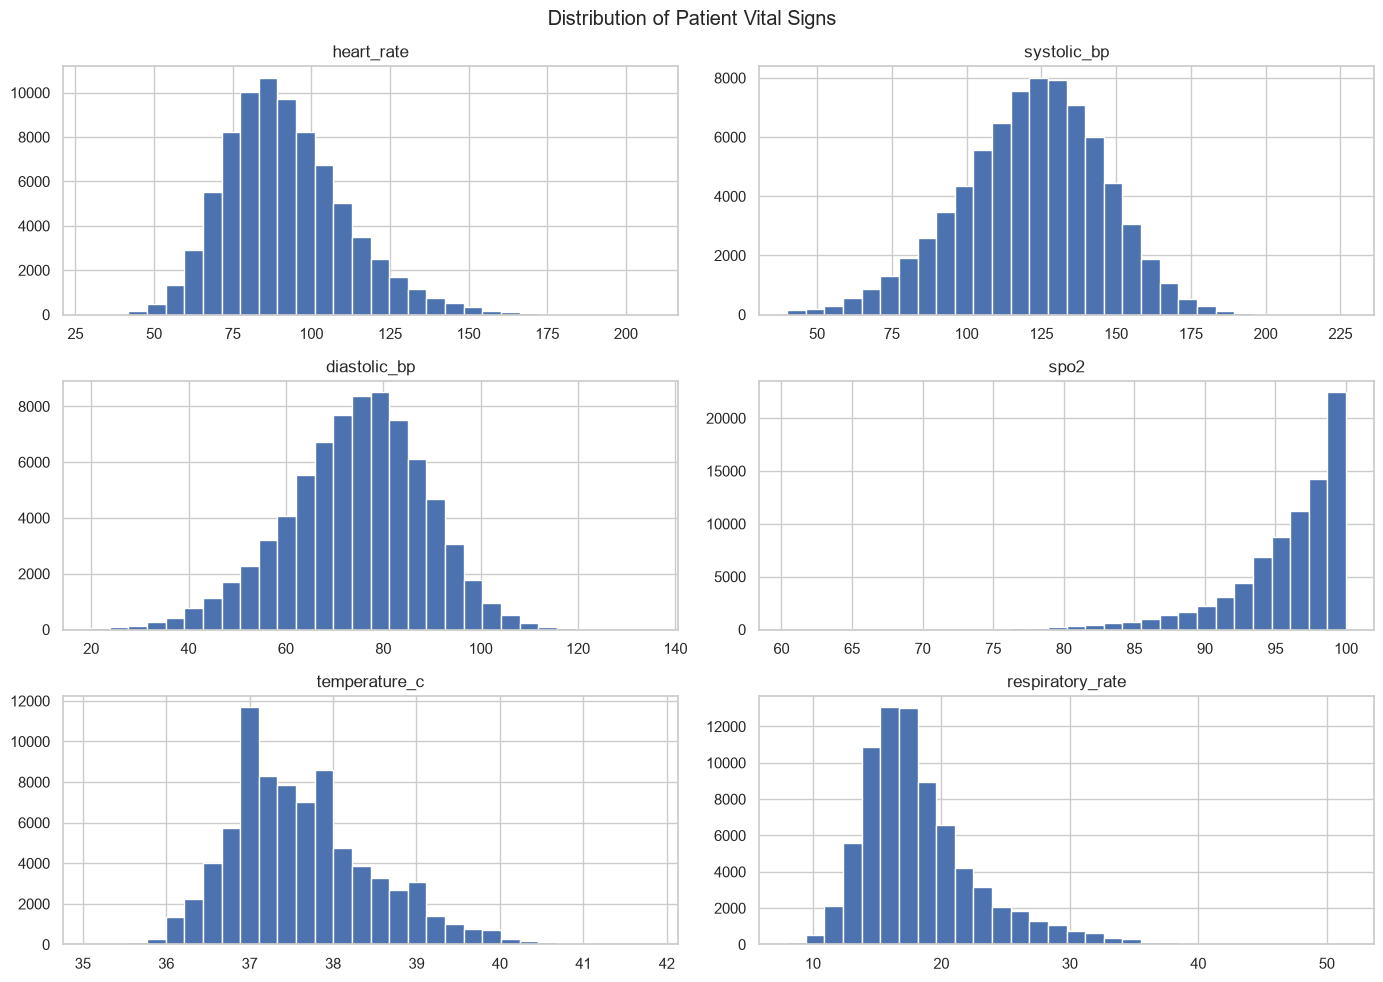

In [20]:
df[vital_columns].hist(
    figsize=(14, 10),
    bins=30
)

plt.suptitle("Distribution of Patient Vital Signs")
plt.tight_layout()
plt.show()

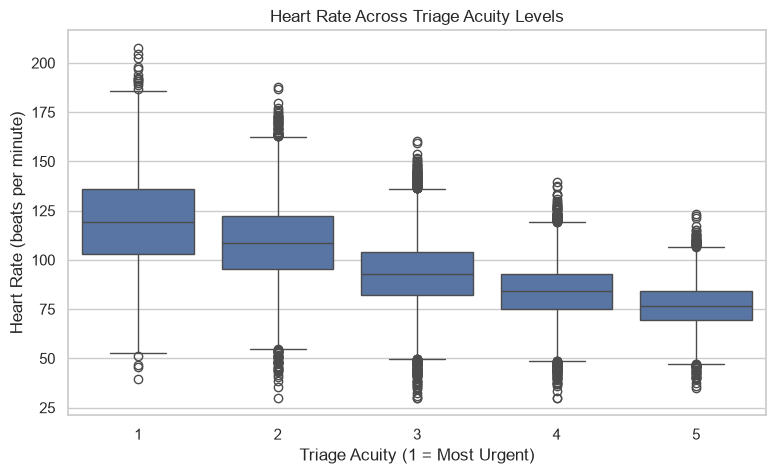

In [21]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="triage_acuity",
    y="heart_rate"
)

plt.title("Heart Rate Across Triage Acuity Levels")
plt.xlabel("Triage Acuity (1 = Most Urgent)")
plt.ylabel("Heart Rate (beats per minute)")

plt.show()

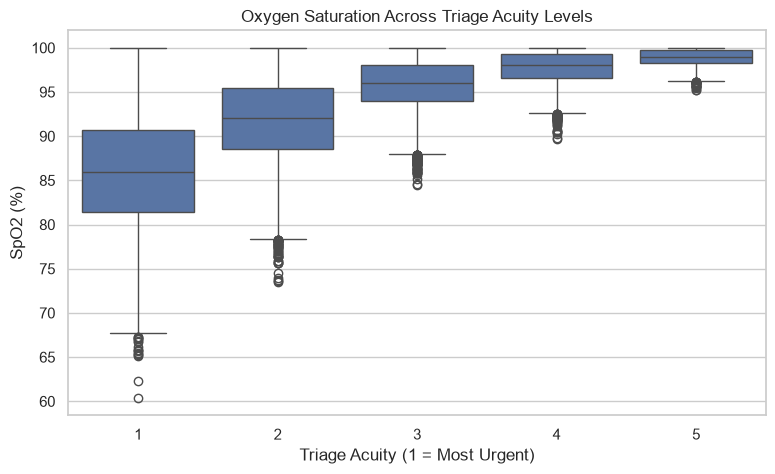

In [22]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="triage_acuity",
    y="spo2"
)

plt.title("Oxygen Saturation Across Triage Acuity Levels")
plt.xlabel("Triage Acuity (1 = Most Urgent)")
plt.ylabel("SpO2 (%)")

plt.show()

In [23]:
df[vital_columns].describe().to_csv(
    "data/vital_signs_summary.csv"
)

print("Vital signs analysis completed!")

Vital signs analysis completed!


In [24]:
# Target column
target = "triage_acuity"

# Columns that should not be used as model inputs
drop_columns = [
    "patient_id",
    "site_id",
    "triage_nurse_id",
    "disposition",
    "ed_los_hours",
    target
]

# Input features
X = df.drop(columns=drop_columns, errors="ignore")

# Target variable
y = df[target]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget categories:")
print(y.value_counts().sort_index())

Input features shape: (80000, 60)
Target shape: (80000,)

Target categories:
triage_acuity
1     3222
2    13439
3    28921
4    23020
5    11398
Name: count, dtype: int64


In [25]:
# Numerical columns
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Categorical and text columns
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nCategorical columns:")
print(categorical_features)

print("\nNumerical columns:")
print(numeric_features)

Numerical features: 47
Categorical features: 13

Categorical columns:
['arrival_mode', 'arrival_day', 'arrival_season', 'shift', 'age_group', 'sex', 'language', 'insurance_type', 'transport_origin', 'pain_location', 'mental_status_triage', 'chief_complaint_system', 'chief_complaint_raw']

Numerical columns:
['arrival_hour', 'arrival_month', 'age', 'num_prior_ed_visits_12m', 'num_prior_admissions_12m', 'num_active_medications', 'num_comorbidities', 'systolic_bp', 'diastolic_bp', 'mean_arterial_pressure', 'pulse_pressure', 'heart_rate', 'respiratory_rate', 'temperature_c', 'spo2', 'gcs_total', 'pain_score', 'weight_kg', 'height_cm', 'bmi', 'shock_index', 'news2_score', 'hx_hypertension', 'hx_diabetes_type2', 'hx_diabetes_type1', 'hx_asthma', 'hx_copd', 'hx_heart_failure', 'hx_atrial_fibrillation', 'hx_ckd', 'hx_liver_disease', 'hx_malignancy', 'hx_obesity', 'hx_depression', 'hx_anxiety', 'hx_dementia', 'hx_epilepsy', 'hx_hypothyroidism', 'hx_hyperthyroidism', 'hx_hiv', 'hx_coagulopathy',

C:\Users\mural\AppData\Local\Temp\ipykernel_30548\29343117.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [26]:
# Identify numerical features
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical and text features
categorical_features = X.select_dtypes(
    include=["object", "category", "bool", "str"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print(categorical_features)

Numerical features: 47
Categorical features: 13
['arrival_mode', 'arrival_day', 'arrival_season', 'shift', 'age_group', 'sex', 'language', 'insurance_type', 'transport_origin', 'pain_location', 'mental_status_triage', 'chief_complaint_system', 'chief_complaint_raw']


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 64000
Testing records: 16000


In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

text_column = "chief_complaint_raw"

# Separate text from other categorical features
categorical_features = [
    col for col in categorical_features
    if col != text_column
]

# Replace missing symptom descriptions with empty strings
X_train = X_train.copy()
X_test = X_test.copy()

X_train[text_column] = X_train[text_column].fillna("")
X_test[text_column] = X_test[text_column].fillna("")

print("Symptom text prepared!")

Symptom text prepared!


In [30]:
# Numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine all features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
        ("text", TfidfVectorizer(
            max_features=3000,
            ngram_range=(1, 2)
        ), text_column)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [31]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training matrix shape:", X_train_processed.shape)
print("Testing matrix shape:", X_test_processed.shape)

Training matrix shape: (64000, 3123)
Testing matrix shape: (16000, 3123)


In [32]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

model.fit(X_train_processed, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [33]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(X_test_processed)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 98.41 %

Classification Report:
              precision    recall  f1-score   support

           1       1.00      0.97      0.99       644
           2       0.98      0.99      0.99      2688
           3       0.97      0.99      0.98      5784
           4       0.99      0.97      0.98      4604
           5       1.00      1.00      1.00      2280

    accuracy                           0.98     16000
   macro avg       0.99      0.98      0.99     16000
weighted avg       0.98      0.98      0.98     16000



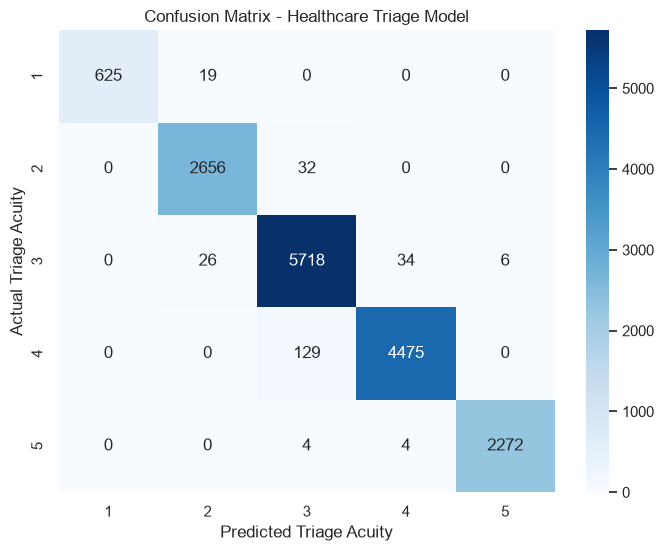

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

labels = [1, 2, 3, 4, 5]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Triage Acuity")
plt.ylabel("Actual Triage Acuity")
plt.title("Confusion Matrix - Healthcare Triage Model")

plt.show()

In [35]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    {
        "preprocessor": preprocessor,
        "model": model
    },
    "models/triage_model_bundle.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [36]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [1]:
print("Number of input features:", len(X.columns))

print("\nInput feature names:")
print(X.columns.tolist())

NameError: name 'X' is not defined

In [2]:
import pandas as pd

# Load your prepared dataset
df = pd.read_csv("data/triage_training_merged.csv")

# Define the target column
target = "triage_acuity"

# Remove ID columns and outcome leakage columns
drop_columns = [
    "patient_id",
    "site_id",
    "triage_nurse_id",
    "disposition",
    "ed_los_hours",
    target
]

# Create input features and target
X = df.drop(columns=drop_columns, errors="ignore")
y = df[target]

print("Dataset loaded successfully!")
print("Number of input features:", len(X.columns))

Dataset loaded successfully!
Number of input features: 60


In [3]:
print(X.columns.tolist())

['arrival_mode', 'arrival_hour', 'arrival_day', 'arrival_month', 'arrival_season', 'shift', 'age', 'age_group', 'sex', 'language', 'insurance_type', 'transport_origin', 'pain_location', 'mental_status_triage', 'chief_complaint_system', 'num_prior_ed_visits_12m', 'num_prior_admissions_12m', 'num_active_medications', 'num_comorbidities', 'systolic_bp', 'diastolic_bp', 'mean_arterial_pressure', 'pulse_pressure', 'heart_rate', 'respiratory_rate', 'temperature_c', 'spo2', 'gcs_total', 'pain_score', 'weight_kg', 'height_cm', 'bmi', 'shock_index', 'news2_score', 'chief_complaint_raw', 'hx_hypertension', 'hx_diabetes_type2', 'hx_diabetes_type1', 'hx_asthma', 'hx_copd', 'hx_heart_failure', 'hx_atrial_fibrillation', 'hx_ckd', 'hx_liver_disease', 'hx_malignancy', 'hx_obesity', 'hx_depression', 'hx_anxiety', 'hx_dementia', 'hx_epilepsy', 'hx_hypothyroidism', 'hx_hyperthyroidism', 'hx_hiv', 'hx_coagulopathy', 'hx_immunosuppressed', 'hx_pregnant', 'hx_substance_use_disorder', 'hx_coronary_artery_dis

In [4]:
import os

print("Current folder:", os.getcwd())

print("Model folder exists:", os.path.exists("models"))

print("Model file exists:",
      os.path.exists("models/triage_model_bundle.pkl"))

Current folder: C:\Users\mural\OneDrive\Desktop\Healthcare_Triage
Model folder exists: True
Model file exists: True


In [5]:
import os

for root, dirs, files in os.walk("."):
    for file in files:
        if file.endswith(".pkl"):
            print(os.path.join(root, file))

.\models\triage_model_bundle.pkl
